# Data Mining Lab: Book Recommender System on a Medallion Data Lake

**Pipeline:** Raw CSV → 🥉 Bronze (untouched Parquet) → 🥈 Silver (cleaned) → 🥇 Gold (model-ready) → Item-based collaborative filtering

**Dataset:** Book-Crossing (Users, Books, Book-Ratings)

## Step 1: Set up the Data Lake and build Bronze

In [1]:
import os, zipfile, urllib.request, html, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

# 1. Create the data lake folders
for d in ["raw", "bronze", "silver", "gold"]:
    os.makedirs(d, exist_ok=True)

# 2. Download the raw files
URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ZIP = "raw/book-crossings.zip"
if not os.path.exists(ZIP):
    urllib.request.urlretrieve(URL, ZIP)
with zipfile.ZipFile(ZIP) as z:
    z.extractall("raw")
print(os.listdir("raw"))

['book-crossings.zip', 'BX-Users.csv', 'BX-Books.csv', 'BX-Book-Ratings.csv']


In [2]:
# 3. Load raw files exactly as they are.
#    - sep=";"           : files are semicolon separated
#    - encoding latin-1  : files are not UTF-8
#    - escapechar "\\"    : titles contain \" sequences that otherwise break quoting
#    - dtype=str         : no type conversion, Bronze stays an untouched copy
READ_KW = dict(sep=";", encoding="latin-1", escapechar="\\", dtype=str, on_bad_lines="skip")

users_raw   = pd.read_csv("raw/BX-Users.csv", **READ_KW)
books_raw   = pd.read_csv("raw/BX-Books.csv", **READ_KW)
ratings_raw = pd.read_csv("raw/BX-Book-Ratings.csv", **READ_KW)

# 4. Add ingestion timestamp and save to bronze/ as Parquet (no cleaning)
ts = pd.Timestamp.now(tz="UTC")
for name, df in [("users", users_raw), ("books", books_raw), ("ratings", ratings_raw)]:
    df["ingestion_timestamp"] = ts
    df.to_parquet(f"bronze/{name}.parquet", index=False)
    print(f"bronze/{name}.parquet  rows={len(df):,}")

# sanity check: no rows were lost (line count of file minus header)
for f, df in [("BX-Users", users_raw), ("BX-Books", books_raw), ("BX-Book-Ratings", ratings_raw)]:
    with open(f"raw/{f}.csv", "rb") as fh:
        n_lines = sum(1 for _ in fh) - 1
    print(f"{f}: file lines={n_lines:,} | loaded rows={len(df):,}")

bronze/users.parquet  rows=278,858


bronze/books.parquet  rows=271,379


bronze/ratings.parquet  rows=1,149,780
BX-Users: file lines=278,859 | loaded rows=278,858
BX-Books: file lines=271,379 | loaded rows=271,379


BX-Book-Ratings: file lines=1,149,780 | loaded rows=1,149,780


## Step 2: Explore the Bronze data (EDA)

In [3]:
users   = pd.read_parquet("bronze/users.parquet")
books   = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("USERS", users), ("BOOKS", books), ("RATINGS", ratings)]:
    print(f"===== {name}  shape={df.shape} =====")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
    print()

===== USERS  shape=(278858, 4) =====
                                   dtype  missing
User-ID                              str        0
Location                             str        0
Age                                  str   110762
ingestion_timestamp  datetime64[us, UTC]        0

===== BOOKS  shape=(271379, 9) =====
                                   dtype  missing
ISBN                                 str        0
Book-Title                           str        0
Book-Author                          str        2
Year-Of-Publication                  str        0
Publisher                            str        2
Image-URL-S                          str        0
Image-URL-M                          str        0
Image-URL-L                          str        0
ingestion_timestamp  datetime64[us, UTC]        0

===== RATINGS  shape=(1149780, 4) =====
                                   dtype  missing
User-ID                              str        0
ISBN                              

**2.1 Shape, dtypes, missing values** → Users: 278,858 rows, `Age` missing in 110,762 (39.7%). Books: 271,379 rows, only 2 missing author and 2 missing publisher. Ratings: 1,149,780 rows, nothing missing. Bronze keeps every column as raw text, so in Silver I will cast ages, years and ratings to numeric types, impute age with the median, and let the 4 incomplete book rows fall out in the ratings filter.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Ratings equal to 0: 716,109 (62.3% of all ratings)


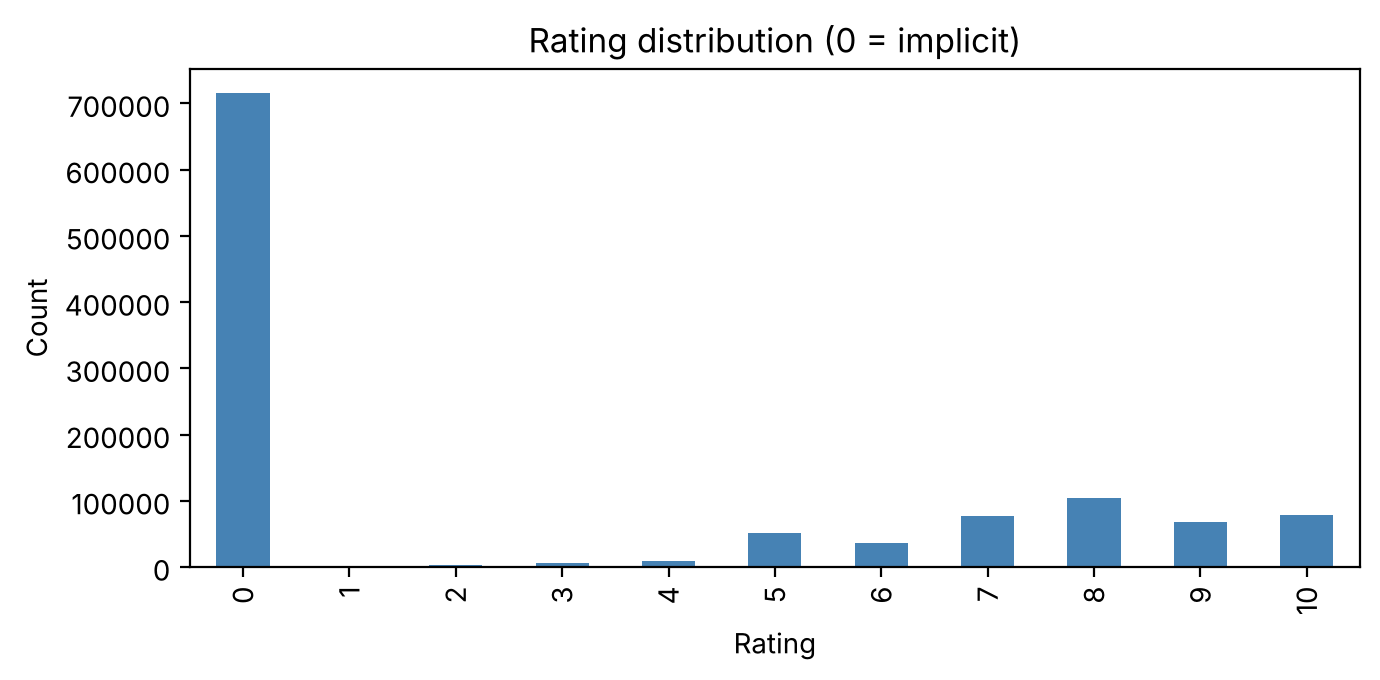

In [4]:
ratings["Book-Rating"] = ratings["Book-Rating"].astype(int)   # EDA copy only, Bronze on disk is unchanged
vc = ratings["Book-Rating"].value_counts().sort_index()
print(vc)
print(f"\nRatings equal to 0: {(ratings['Book-Rating']==0).sum():,} "
      f"({(ratings['Book-Rating']==0).mean()*100:.1f}% of all ratings)")
fig, ax = plt.subplots(figsize=(7, 3.5))
vc.plot.bar(ax=ax, color="steelblue"); ax.set_title("Rating distribution (0 = implicit)")
ax.set_xlabel("Rating"); ax.set_ylabel("Count"); plt.tight_layout(); plt.show()

**2.2 Rating distribution** → 716,109 of 1,149,780 ratings (62.3%) are 0, meaning *no explicit rating*; the real 1–10 ratings are skewed high (mode = 8). In Silver I will drop all 0 ratings and keep only 1–10 (433,671 rows).

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Age < 5   : 882
Age > 100 : 366
Age missing: 110,762 (39.7%)

 count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Year == 0 : 4,619
Year > 2026 (future): 11
Year not numeric (shifted/corrupt rows): 0


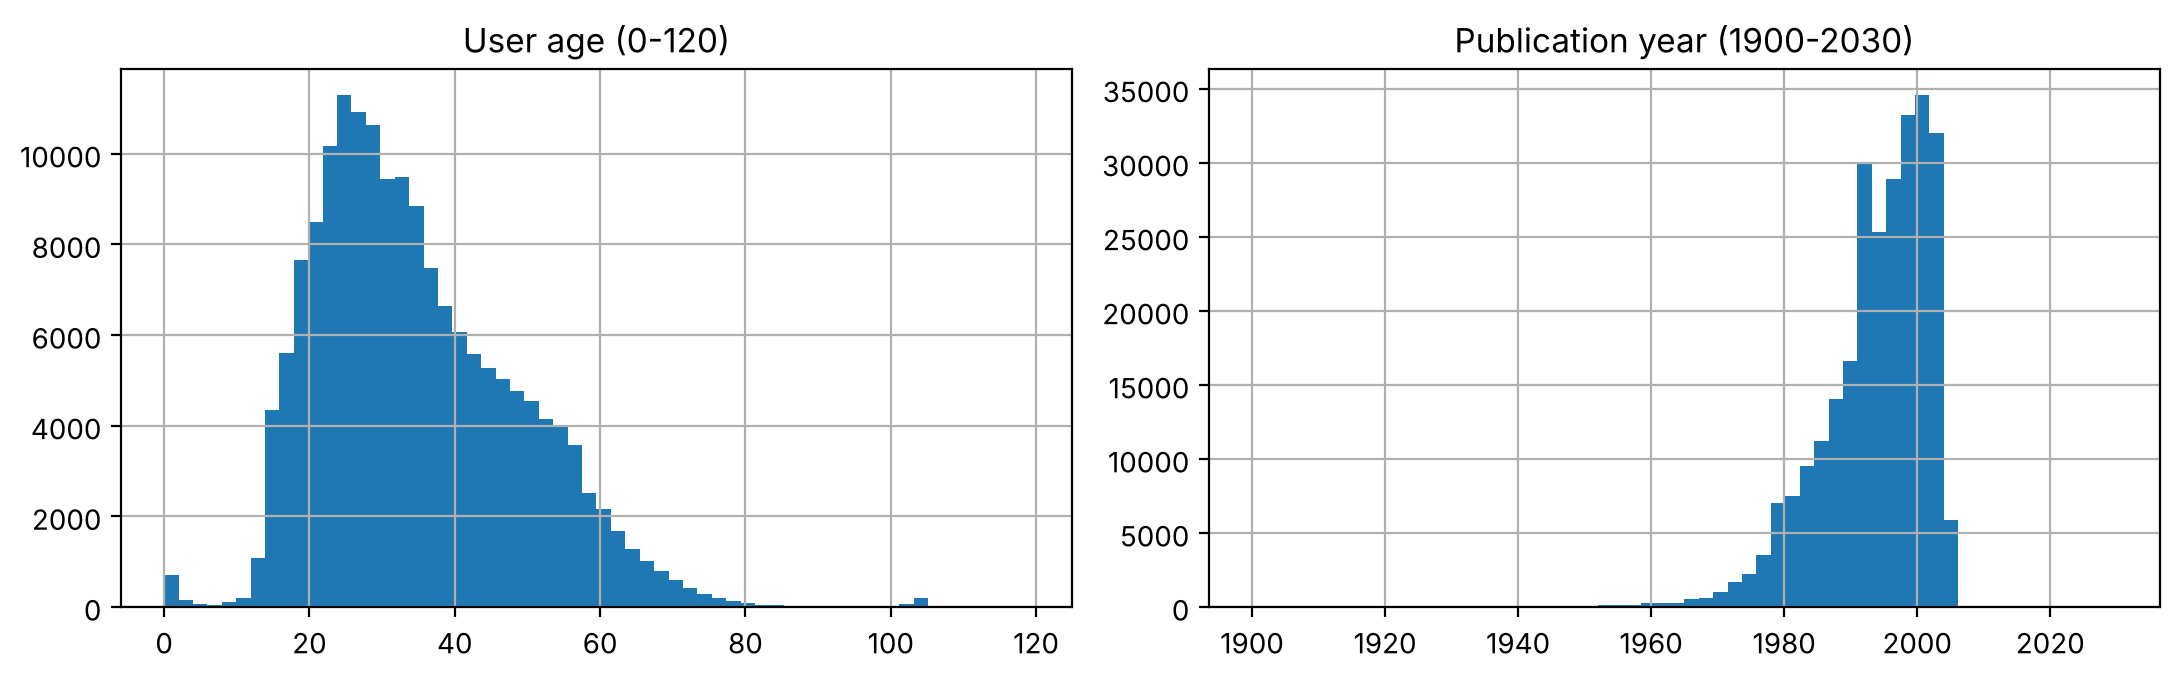

In [5]:
age = pd.to_numeric(users["Age"], errors="coerce")
print(age.describe())
print(f"\nAge < 5   : {(age < 5).sum():,}")
print(f"Age > 100 : {(age > 100).sum():,}")
print(f"Age missing: {age.isna().sum():,} ({age.isna().mean()*100:.1f}%)")

year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
print("\n", year.describe())
print(f"\nYear == 0 : {(year == 0).sum():,}")
print(f"Year > {datetime.date.today().year} (future): {(year > datetime.date.today().year).sum():,}")
print(f"Year not numeric (shifted/corrupt rows): {year.isna().sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
age[(age >= 0) & (age <= 120)].hist(bins=60, ax=ax[0]); ax[0].set_title("User age (0-120)")
year[(year >= 1900) & (year <= 2030)].hist(bins=60, ax=ax[1]); ax[1].set_title("Publication year (1900-2030)")
plt.tight_layout(); plt.show()

**2.3 Ages** → Ages range from 0 to 244: 882 are below 5 and 366 above 100 (impossible), plus 39.7% missing. In Silver I will set ages <5 or >100 to null and fill all nulls with the median age (32).

**2.4 Publication years** → 4,619 books have publication year 0 and 11 have future years (up to 2050). In Silver I will set these to null and keep them as null, since a year is not needed by the recommender.

       all ratings / user  all ratings / book  explicit ratings / user  explicit ratings / book
count           105283.00           340556.00                 77805.00                185973.00
mean                10.92                3.38                     5.57                     2.33
std                 90.56               12.44                    44.00                     6.83
min                  1.00                1.00                     1.00                     1.00
25%                  1.00                1.00                     1.00                     1.00
50%                  1.00                1.00                     1.00                     1.00
75%                  4.00                2.00                     3.00                     2.00
max              13602.00             2502.00                  8524.00                   707.00

Share of users with explicit ratings: <5 = 81.7% | <10 = 90.6%
Share of books with explicit ratings: <5 = 92.2% | <10 = 97.0%
Users wit

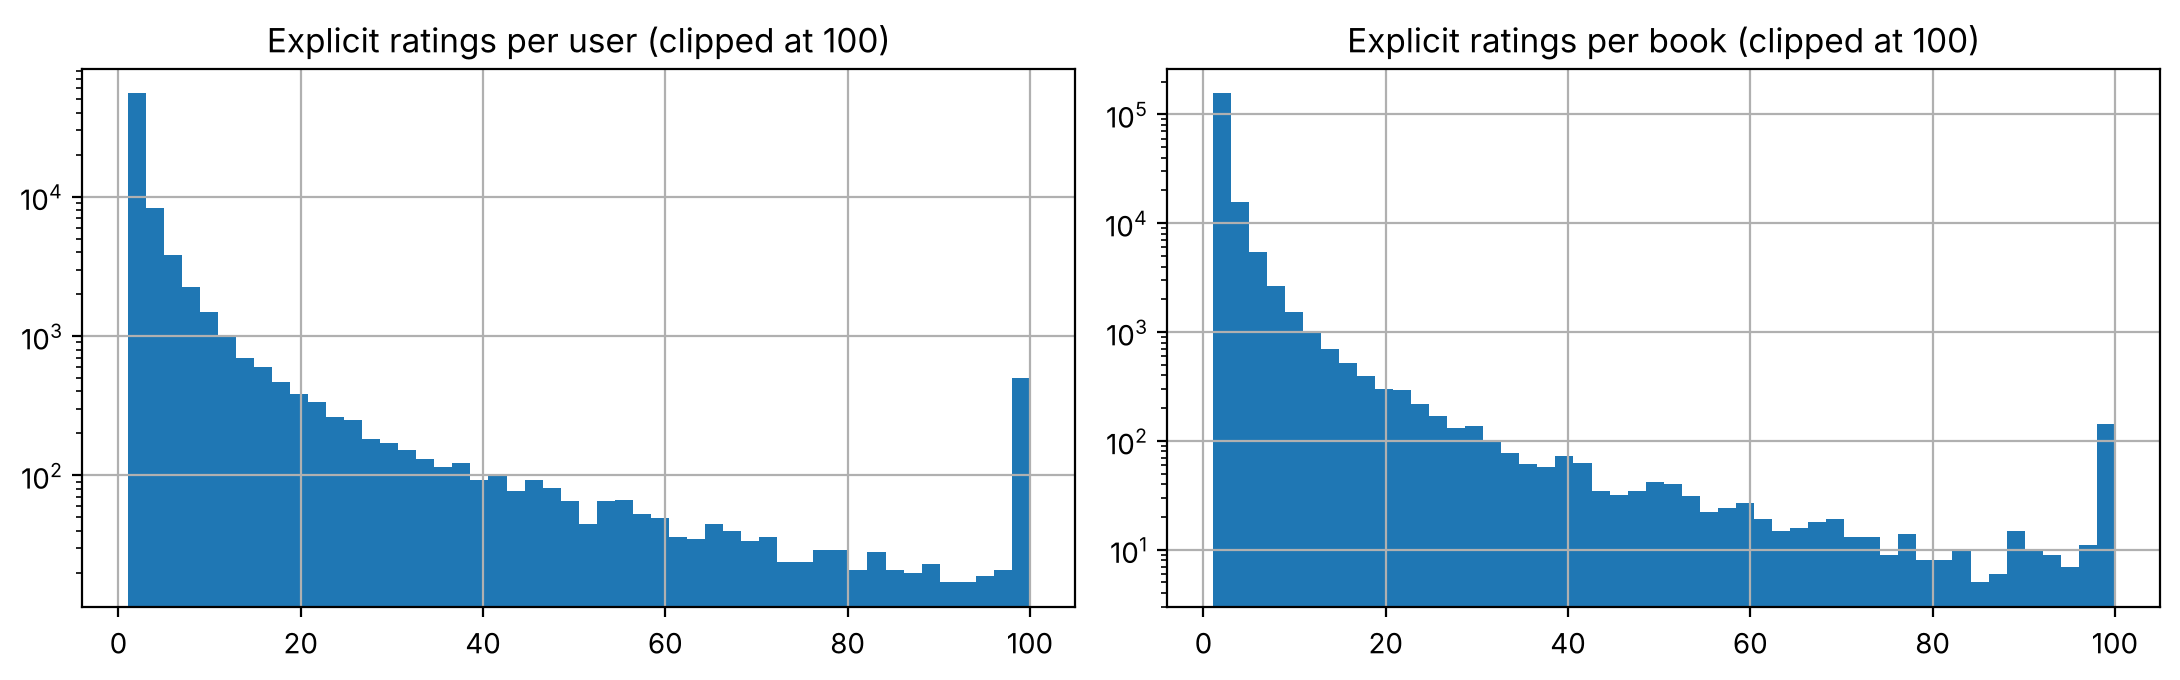

In [6]:
per_user = ratings.groupby("User-ID").size()
per_book = ratings.groupby("ISBN").size()
expl = ratings[ratings["Book-Rating"] > 0]
per_user_e = expl.groupby("User-ID").size()
per_book_e = expl.groupby("ISBN").size()

summary = pd.DataFrame({
    "all ratings / user":      per_user.describe(),
    "all ratings / book":      per_book.describe(),
    "explicit ratings / user": per_user_e.describe(),
    "explicit ratings / book": per_book_e.describe(),
})
print(summary.round(2))

print("\nShare of users with explicit ratings: <5 =", f"{(per_user_e<5).mean()*100:.1f}%",
      "| <10 =", f"{(per_user_e<10).mean()*100:.1f}%")
print("Share of books with explicit ratings: <5 =", f"{(per_book_e<5).mean()*100:.1f}%",
      "| <10 =", f"{(per_book_e<10).mean()*100:.1f}%")
for k in (5, 10, 20):
    print(f"Users with >= {k} explicit ratings: {(per_user_e>=k).sum():,} | books with >= {k}: {(per_book_e>=k).sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
per_user_e.clip(upper=100).hist(bins=50, ax=ax[0], log=True); ax[0].set_title("Explicit ratings per user (clipped at 100)")
per_book_e.clip(upper=100).hist(bins=50, ax=ax[1], log=True); ax[1].set_title("Explicit ratings per book (clipped at 100)")
plt.tight_layout(); plt.show()

**2.5 Ratings per user and per book** → The median user and the median book each have just 1 explicit rating; 81.7% of users have <5 ratings and 97.0% of books have <10, with an extreme tail (one user has 8,524 ratings, one book 707). In Silver I will keep only users and books above a minimum number of ratings (threshold justified in 3.8).

In [7]:
def sparsity(df):
    n_u, n_b = df["User-ID"].nunique(), df["ISBN"].nunique()
    density = len(df) / (n_u * n_b)
    return n_u, n_b, len(df), density * 100, 100 - density * 100

for label, df in [("all ratings (incl. 0)", ratings), ("explicit ratings only (1-10)", expl)]:
    n_u, n_b, n_r, dens, sparse = sparsity(df)
    print(f"{label}: {n_u:,} users x {n_b:,} books, {n_r:,} ratings -> density {dens:.5f}% | sparsity {sparse:.3f}%")

all ratings (incl. 0): 105,283 users x 340,556 books, 1,149,780 ratings -> density 0.00321% | sparsity 99.997%
explicit ratings only (1-10): 77,805 users x 185,973 books, 433,671 ratings -> density 0.00300% | sparsity 99.997%


**2.6 Matrix sparsity** → Only about 0.003% of possible user-book pairs have a rating, i.e. the matrix is 99.997% empty. In Gold I will store the matrix as a SciPy sparse CSR matrix (a dense matrix would not fit in memory) and use a brute-force cosine k-NN that works directly on sparse rows.

## Step 3: Clean the data → Silver layer

In [8]:
users   = pd.read_parquet("bronze/users.parquet")
books   = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")
log = {}   # row counts after each cleaning step (for the report)

# ---- 3.0 Normalise keys first (strip spaces, upper-case ISBN) so that
#      "034545104x" and "034545104X" are recognised as the same book ----------
users["User-ID"]   = users["User-ID"].str.strip()
ratings["User-ID"] = ratings["User-ID"].str.strip()
books["ISBN"]      = books["ISBN"].str.strip().str.upper()
ratings["ISBN"]    = ratings["ISBN"].str.strip().str.upper()

# ---- 3.1 Remove duplicates ------------------------------------------------
# ingestion_timestamp is identical on every row so it never hides a duplicate;
# duplicates are checked on the business keys.
n0 = (len(users), len(books), len(ratings))
users   = users.drop_duplicates(subset="User-ID")
books   = books.drop_duplicates(subset="ISBN")
ratings = ratings.drop_duplicates(subset=["User-ID", "ISBN"])
print("Duplicates removed -> users:", n0[0]-len(users), "| books:", n0[1]-len(books), "| ratings:", n0[2]-len(ratings))

# ---- 3.2 Type casting + remove 0 ratings, keep 1-10 -----------------------
ratings["Book-Rating"] = pd.to_numeric(ratings["Book-Rating"], errors="coerce")
n = len(ratings)
ratings = ratings[ratings["Book-Rating"].between(1, 10)].copy()
ratings["Book-Rating"] = ratings["Book-Rating"].astype("int8")
print(f"Removed {n-len(ratings):,} implicit (0) ratings -> {len(ratings):,} explicit ratings remain")

# ---- 3.3 Fix ages: <5 or >100 -> null, then median fill ------------------
users["Age"] = pd.to_numeric(users["Age"], errors="coerce")
bad_age = (users["Age"] < 5) | (users["Age"] > 100)
print(f"Impossible ages set to null: {bad_age.sum():,}")
users.loc[bad_age, "Age"] = np.nan
median_age = users["Age"].median()
users["Age"] = users["Age"].fillna(median_age).astype("int16")
print(f"Median age used for filling: {median_age:.0f}")

# ---- 3.4 Split Location into city / state / country ----------------------
def clean_text(s):
    s = s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    return s.replace({"": pd.NA, "n/a": pd.NA, "na": pd.NA, "null": pd.NA})

loc = users["Location"].astype("string").str.lower()
parts = loc.str.split(",")
users["city"]    = clean_text(parts.str[0])
users["state"]   = clean_text(parts.str[1].where(parts.str.len() >= 3))
users["country"] = clean_text(parts.str[-1])
users = users.drop(columns=["Location"])

# ---- 3.5 Fix publication years: 0 / future / non-numeric -> null --------
this_year = datetime.date.today().year
books["Year-Of-Publication"] = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
bad_year = (books["Year-Of-Publication"] == 0) | (books["Year-Of-Publication"] > this_year) | books["Year-Of-Publication"].isna()
print(f"Invalid publication years set to null: {bad_year.sum():,}")
books.loc[bad_year, "Year-Of-Publication"] = np.nan
books["Year-Of-Publication"] = books["Year-Of-Publication"].astype("Int16")

# ---- 3.6 Clean text columns, drop image URL columns -----------------------
books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
for c in ["Book-Title", "Book-Author", "Publisher"]:
    books[c] = clean_text(books[c].astype("string").map(lambda x: html.unescape(x) if isinstance(x, str) else x)).str.title()
    # str.title() turns "wife's" into "Wife'S"; repair apostrophe endings
    books[c] = books[c].str.replace(r"(?<=[A-Za-z])'([A-Z])", lambda m: "'" + m.group(1).lower(), regex=True)
for c in ["city", "state", "country"]:
    users[c] = users[c].str.title()

# ---- 3.7 Referential integrity -------------------------------------------
n = len(ratings)
ratings = ratings[ratings["ISBN"].isin(books["ISBN"]) & ratings["User-ID"].isin(users["User-ID"])]
print(f"Orphan ratings removed (user or book missing): {n-len(ratings):,}")

Duplicates removed -> users: 0 | books: 315 | ratings: 0


Removed 716,109 implicit (0) ratings -> 433,671 explicit ratings remain
Impossible ages set to null: 1,248
Median age used for filling: 32


Invalid publication years set to null: 4,623


Orphan ratings removed (user or book missing): 49,818


### 3.8 Minimum-ratings threshold (chosen from the EDA)

**Chosen threshold: every user has ≥ 5 ratings and every book has ≥ 10 ratings.**

- **Why filter at all:** the EDA shows the median user and book has only 1 rating, so most items carry no signal. Cosine similarity between two books needs *shared raters*; with a single co-rater the cosine is exactly 1.0, which is pure noise.
- **Why books ≥ 10:** a book needs enough raters for its similarity scores to be stable. Only 5,645 books have ≥ 10 explicit ratings.
- **Why users ≥ 5 (not 10):** a user needs a handful of ratings to have any "liked" seed books, but being stricter throws away too much data. The table below shows that (10, 10) would shrink the data to 1,820 users and 2,030 books (about 40% fewer ratings than (5, 10)), while (5, 5) keeps many books with only 5 raters and therefore noisy similarities.
- **Result:** (5, 10) is the compromise, keeping 4,749 users, 3,060 books and 69,346 ratings (matrix sparsity drops from 99.997% to 99.52%).
- Because removing books can push a user under the threshold (and vice-versa), the filter is applied repeatedly until it is stable.

In [9]:
MIN_USER_RATINGS = 5
MIN_BOOK_RATINGS = 10

# Compare candidate thresholds (iterating until stable, because dropping books changes user counts and vice-versa)
def apply_threshold(df, min_u, min_b):
    while True:
        uc = df["User-ID"].value_counts(); bc = df["ISBN"].value_counts()
        out = df[df["User-ID"].isin(uc[uc >= min_u].index) & df["ISBN"].isin(bc[bc >= min_b].index)]
        if len(out) == len(df):
            return out
        df = out

rows = []
for mu, mb in [(5, 5), (5, 10), (10, 5), (10, 10)]:
    r_ = apply_threshold(ratings, mu, mb)
    nu, nb = r_["User-ID"].nunique(), r_["ISBN"].nunique()
    rows.append({"min_user": mu, "min_book": mb, "ratings": len(r_), "users": nu, "books": nb,
                 "sparsity_%": round(100 - 100*len(r_)/max(nu*nb, 1), 2)})
print(pd.DataFrame(rows).to_string(index=False))

ratings = apply_threshold(ratings, MIN_USER_RATINGS, MIN_BOOK_RATINGS)
users = users[users["User-ID"].isin(ratings["User-ID"])]
books = books[books["ISBN"].isin(ratings["ISBN"])]
print(f"\nFINAL SILVER -> users={len(users):,} | books={len(books):,} | ratings={len(ratings):,}")

 min_user  min_book  ratings  users  books  sparsity_%
        5         5   115332   6858   9092       99.82
        5        10    69346   4749   3060       99.52
       10         5    81101   2903   6820       99.59
       10        10    41469   1820   2030       98.88



FINAL SILVER -> users=4,749 | books=3,060 | ratings=69,346


In [10]:
# Add silver processing timestamp and save
silver_ts = pd.Timestamp.now(tz="UTC")
for name, df in [("users", users), ("books", books), ("ratings", ratings)]:
    df = df.drop(columns=["ingestion_timestamp"], errors="ignore").assign(silver_timestamp=silver_ts)
    df.reset_index(drop=True).to_parquet(f"silver/{name}.parquet", index=False)

# quick quality report on Silver
s_users, s_books, s_ratings = (pd.read_parquet(f"silver/{n}.parquet") for n in ["users", "books", "ratings"])
print(s_users.head(), "\n"); print(s_books.head(), "\n"); print(s_ratings.head())
print("\nMissing values per column:")
print(s_users.isna().sum().to_dict()); print(s_books.isna().sum().to_dict()); print(s_ratings.isna().sum().to_dict())
print("Age range:", s_users["Age"].min(), "-", s_users["Age"].max(),
      "| Year range:", s_books["Year-Of-Publication"].min(), "-", s_books["Year-Of-Publication"].max(),
      "| Rating range:", s_ratings["Book-Rating"].min(), "-", s_ratings["Book-Rating"].max())

  User-ID  Age             city      state country                 silver_timestamp
0     243   32      Arden Hills  Minnesota     Usa 2026-11-26 17:58:17.989860+00:00
1     244   32  College Station      Texas     Usa 2026-11-26 17:58:17.989860+00:00
2     254   24      Minneapolis  Minnesota     Usa 2026-11-26 17:58:17.989860+00:00
3     388   35        Nashville  Tennessee     Usa 2026-11-26 17:58:17.989860+00:00
4     507   32            Dumas   Arkansas     Usa 2026-11-26 17:58:17.989860+00:00 

         ISBN                            Book-Title       Book-Author  Year-Of-Publication         Publisher                 silver_timestamp
0  0399135782                The Kitchen God'S Wife           Amy Tan                 1991  Putnam Pub Group 2026-11-26 17:58:17.989860+00:00
1  0440234743                         The Testament      John Grisham                 1999              Dell 2026-11-26 17:58:17.989860+00:00
2  0452264464  Beloved (Plume Contemporary Fiction)     Toni Morriso

## Step 4: Build the Gold layer

In [11]:
import json
silver_users   = pd.read_parquet("silver/users.parquet")
silver_books   = pd.read_parquet("silver/books.parquet")
silver_ratings = pd.read_parquet("silver/ratings.parquet")

# ---- 4.1 Index mappings (user/book id -> matrix row/column) ---------------
user_ids = np.sort(silver_ratings["User-ID"].unique())
book_ids = np.sort(silver_ratings["ISBN"].unique())
user_idx = pd.DataFrame({"User-ID": user_ids, "user_idx": np.arange(len(user_ids))})
book_idx = pd.DataFrame({"ISBN": book_ids, "book_idx": np.arange(len(book_ids))})

# ---- 4.2 Sparse user x book rating matrix (CSR) ---------------------------
r = (silver_ratings.merge(user_idx, on="User-ID").merge(book_idx, on="ISBN"))
rating_matrix = sp.csr_matrix(
    (r["Book-Rating"].astype("float32"), (r["user_idx"], r["book_idx"])),
    shape=(len(user_ids), len(book_ids)))
sp.save_npz("gold/rating_matrix.npz", rating_matrix)
user_idx.to_parquet("gold/user_index.parquet", index=False)
book_idx.to_parquet("gold/book_index.parquet", index=False)
print("Rating matrix (users x books):", rating_matrix.shape, "| stored ratings:", rating_matrix.nnz,
      f"| sparsity: {100*(1 - rating_matrix.nnz/(rating_matrix.shape[0]*rating_matrix.shape[1])):.2f}%")

# ---- 4.3 Book lookup table (id, title, author) ----------------------------
book_lookup = (silver_books[["ISBN", "Book-Title", "Book-Author"]]
               .merge(book_idx, on="ISBN")
               .rename(columns={"ISBN": "book_id", "Book-Title": "title", "Book-Author": "author"})
               .sort_values("book_idx").reset_index(drop=True))
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

# ---- 4.4 User-level and book-level aggregates -----------------------------
user_stats = (silver_ratings.groupby("User-ID")["Book-Rating"]
              .agg(avg_rating="mean", num_ratings="count").round(3).reset_index())
book_stats = (silver_ratings.groupby("ISBN")["Book-Rating"]
              .agg(avg_rating="mean", num_ratings="count").round(3).reset_index()
              .merge(silver_books[["ISBN", "Book-Title", "Book-Author"]], on="ISBN"))
user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print(os.listdir("gold"))
print(book_lookup.head(), "\n"); print(user_stats.head(), "\n")
print(book_stats.sort_values("num_ratings", ascending=False).head(10))

Rating matrix (users x books): (4749, 3060) | stored ratings: 69346 | sparsity: 99.52%
['user_index.parquet', 'user_stats.parquet', 'rating_matrix.npz', 'book_lookup.parquet', 'book_index.parquet', 'book_stats.parquet']
      book_id                             title               author  book_idx
0  000649840X                     Angelas Ashes        Frank Mccourt         0
1  0007154615                  Unless : A Novel        Carol Shields         1
2  0020198906                            Joshua     Joseph F Girzone         2
3  0020199600            Great Gatsby (Reissue)  F. Scott Fitzgerald         3
4  0020442203  Lion, The Witch And The Wardrobe           C.S. Lewis         4 

  User-ID  avg_rating  num_ratings
0  100009       8.000           11
1  100053       7.200            5
2  100088       9.333           18
3  100223       7.800            5
4  100227       9.000           14 

            ISBN  avg_rating  num_ratings                                                   

## Step 5: Item-based collaborative filtering

In [12]:
# ---- 5.1 Load the matrix from Gold; rows = books, columns = users --------
R_user_book = sp.load_npz("gold/rating_matrix.npz")
user_idx    = pd.read_parquet("gold/user_index.parquet")
book_idx    = pd.read_parquet("gold/book_index.parquet")
lookup      = pd.read_parquet("gold/book_lookup.parquet")

R_book_user = R_user_book.T.tocsr()        # books x users
print("Book x User matrix:", R_book_user.shape)

# ---- 5.2 Cosine similarity between books (brute-force NearestNeighbors) ---
knn = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(R_book_user)

# helper structures
uid_to_row = dict(zip(user_idx["User-ID"], user_idx["user_idx"]))
title_to_idx = lookup.copy()
title_to_idx["title_l"] = title_to_idx["title"].str.lower()
n_ratings_per_book = np.asarray((R_book_user > 0).sum(axis=1)).ravel()
title_to_idx["n_ratings"] = n_ratings_per_book

Book x User matrix: (3060, 4749)


In [13]:
import re
def title_key(t):
    # Edition-insensitive key: drop "(series info)" and ": subtitle", lower-case.
    # Several ISBNs (paperback/hardcover/reissue) can be the same book.
    t = t.lower()
    while True:                                   # strip innermost "(...)" repeatedly to handle nested brackets
        t2 = re.sub(r"\s*\([^()]*\)", "", t)
        if t2 == t: break
        t = t2
    return t.split(":")[0].strip()

title_to_idx["key"] = title_to_idx["title"].map(title_key)
book_key = title_to_idx["key"].values

def find_book(title):
    """Resolve a (possibly partial) title to a book_idx. If several editions share the title, use the most-rated one."""
    t = title.lower().strip()
    hit = title_to_idx[title_to_idx["title_l"] == t]
    if hit.empty:
        hit = title_to_idx[title_to_idx["title_l"].str.contains(t, regex=False)]
    if hit.empty:
        raise ValueError(f"'{title}' not found (it may have been filtered out in Silver).")
    return int(hit.sort_values("n_ratings", ascending=False).iloc[0]["book_idx"])

# ---- 5.3 Similar books for a title ---------------------------------------
def similar_books(title, k=10):
    i = find_book(title)
    dist, ind = knn.kneighbors(R_book_user[i], n_neighbors=k * 3 + 1)   # extra neighbours so we can drop other editions
    seen, rows = {book_key[i]}, []                                      # skip the book itself and its other editions
    for d, j in zip(dist[0], ind[0]):
        if book_key[j] in seen:
            continue
        seen.add(book_key[j]); rows.append((j, 1 - d))
        if len(rows) == k:
            break
    out = lookup.iloc[[j for j, _ in rows]][["title", "author"]].copy()
    out["similarity"] = [round(s_, 3) for _, s_ in rows]
    print(f"Books similar to: '{lookup.iloc[i]['title']}' by {lookup.iloc[i]['author']}")
    return out.reset_index(drop=True)

popular = title_to_idx.sort_values("n_ratings", ascending=False)["title"].head(3).tolist()
print("Most-rated books in the data:", popular)
similar_books(popular[0])

Most-rated books in the data: ['The Lovely Bones: A Novel', 'The Da Vinci Code', 'The Red Tent (Bestselling Backlist)']
Books similar to: 'The Lovely Bones: A Novel' by Alice Sebold


,title,author,similarity
0,Lucky : A Memoir,Alice Sebold,0.169
1,Where The Heart Is (Oprah'S Book Club (Paperback)),Billie Letts,0.166
2,The Da Vinci Code,Dan Brown,0.142
3,Good In Bed,Jennifer Weiner,0.132
4,Nights In Rodanthe,Nicholas Sparks,0.131
5,The Book Of Ruth (Oprah'S Book Club (Paperback)),Jane Hamilton,0.127
6,The Pact: A Love Story,Jodi Picoult,0.126
7,The Pilot'S Wife : A Novel,Anita Shreve,0.124
8,The Dive From Clausen'S Pier (Alex Awards),Ann Packer,0.121
9,She'S Come Undone (Oprah'S Book Club),Wally Lamb,0.120


In [14]:
# ---- 5.4 recommend(user_id, n) -------------------------------------------
def liked_books(user_id, min_rating=8, fallback_top=5):
    row = R_user_book[uid_to_row[str(user_id)]]
    items, vals = row.indices, row.data
    mask = vals >= min_rating
    if mask.sum() == 0:                                  # fallback: the user's best-rated books
        order = np.argsort(-vals)[:fallback_top]
        return items[order], vals[order]
    return items[mask], vals[mask]

def recommend(user_id, n=10, per_book_neighbors=50, min_rating=8):
    user_id = str(user_id)
    if user_id not in uid_to_row:
        raise ValueError(f"User {user_id} not in the Gold layer (filtered out or unknown).")
    read = set(R_user_book[uid_to_row[user_id]].indices)           # every book already rated
    read_keys = {book_key[j] for j in read}                        # ...including other editions of those books
    items, vals = liked_books(user_id, min_rating)

    dist, ind = knn.kneighbors(R_book_user[items], n_neighbors=per_book_neighbors + 1)
    scores = {}
    for rating, d_row, i_row in zip(vals, dist, ind):
        for d, j in zip(d_row, i_row):
            if j in read or book_key[j] in read_keys:              # drop already-read books (any edition)
                continue
            scores[j] = scores.get(j, 0.0) + (1 - d) * rating      # similarity weighted by user's rating
    top, seen = [], set()
    for j, sc in sorted(scores.items(), key=lambda kv: -kv[1]):    # best first; keep one edition per title
        if book_key[j] in seen:
            continue
        seen.add(book_key[j]); top.append((j, sc))
        if len(top) == n:
            break
    out = lookup.iloc[[j for j, _ in top]][["title", "author"]].copy()
    out["score"] = [round(s, 3) for _, s in top]
    return out.reset_index(drop=True)

## Step 6: Demo and sanity check

In [15]:
# pick 3 users with a moderate history (enough taste signal, not extreme power users)
n_per_user = np.diff(R_user_book.indptr)
cand = user_idx[(n_per_user >= 20) & (n_per_user <= 60)]["User-ID"].sample(3, random_state=42).tolist()

for uid in cand:
    items, vals = liked_books(uid)
    liked = lookup.iloc[items][["title", "author"]].assign(rating=vals.astype(int)).sort_values("rating", ascending=False)
    recs = recommend(uid, n=10)

    print("=" * 100)
    print(f"USER {uid}  ({n_per_user[uid_to_row[uid]]} books rated)")
    print("-" * 100)
    print("Books the user rated highly (>= 8), top 10:")
    print(liked.head(10).to_string(index=False))
    print("\nRecommended books:")
    print(recs.to_string(index=False))

    # sanity checks
    read_keys = {book_key[j] for j in R_user_book[uid_to_row[uid]].indices}
    assert len(recs) == 10, "should return 10 recommendations"
    assert not (set(recs["title"].map(title_key)) & read_keys), "recommended a book the user already read!"
    print("\n✔ sanity checks passed: 10 recommendations, none already read\n")

USER 69389  (60 books rated)
----------------------------------------------------------------------------------------------------
Books the user rated highly (>= 8), top 10:
                                                                title             author  rating
                                    Seven Up (A Stephanie Plum Novel)    Janet Evanovich       9
         Hard Eight : A Stephanie Plum Novel (A Stephanie Plum Novel)    Janet Evanovich       9
                                                   The Hours: A Novel Michael Cunningham       9
                                 To The Nines: A Stephanie Plum Novel    Janet Evanovich       9
                               Four To Score (A Stephanie Plum Novel)    Janet Evanovich       9
Three To Get Deadly : A Stephanie Plum Novel (A Stephanie Plum Novel)    Janet Evanovich       9
                                             White Oleander : A Novel        Janet Fitch       9
                                                  

In [16]:
# Extra sanity check: do similar_books() results look sensible for a few popular titles?
for t in popular[1:3]:
    display(similar_books(t))

Books similar to: 'The Da Vinci Code' by Dan Brown


,title,author,similarity
0,Angels & Demons,Dan Brown,0.222
1,Middlesex: A Novel,Jeffrey Eugenides,0.142
2,The Lovely Bones: A Novel,Alice Sebold,0.142
3,Street Dreams,Faye Kellerman,0.130
4,The Face,Dean Koontz,0.127
5,Nights In Rodanthe,Nicholas Sparks,0.123
6,The Narrows: A Novel,Michael Connelly,0.120
7,Digital Fortress : A Thriller,Dan Brown,0.115
8,No Second Chance,Harlan Coben,0.115
9,The Secret Life Of Bees,Sue Monk Kidd,0.114


Books similar to: 'The Red Tent (Bestselling Backlist)' by Anita Diamant


,title,author,similarity
0,The Poisonwood Bible: A Novel,Barbara Kingsolver,0.145
1,The Secret Life Of Bees,Sue Monk Kidd,0.140
2,Fried Green Tomatoes At The Whistle Stop Cafe,Fannie Flagg,0.138
3,Girl With A Pearl Earring,Tracy Chevalier,0.137
4,The Hours: A Novel,Michael Cunningham,0.135
5,Waiting (Vintage International),Ha Jin,0.133
6,Fall On Your Knees (Oprah #45),Ann-Marie Macdonald,0.131
7,Pope Joan (Ballantine Reader'S Circle),Donna Woolfolk Cross,0.123
8,The Handmaid'S Tale,Margaret Atwood,0.122
9,Balzac And The Little Chinese Seamstress : A Novel,Dai Sijie,0.122


## Summary and limitations

**Pipeline results**

| Layer | Content |
|---|---|
| Bronze | 278,858 users · 271,379 books · 1,149,780 ratings, raw text + `ingestion_timestamp` |
| Silver | 4,749 users · 3,060 books · 69,346 explicit ratings (≥5 ratings/user, ≥10 ratings/book) |
| Gold | sparse 4,749 × 3,060 rating matrix, book lookup, user/book aggregates |

**Design decisions**
- *Several ISBNs can be the same book* (paperback, hardcover, reissue). Recommendations exclude any edition of a book the user has read and show only one edition per title.
- *"Rated highly"* = rating ≥ 8 (falls back to the user's top 5 if none). Candidate score = Σ similarity × user's rating over the user's liked books.

**Limitations**
- Cosine on raw ratings favours popular books and ignores that some users rate more generously; mean-centred ratings (adjusted cosine) would be a natural improvement.
- Filtering removes cold-start users/books, so these cannot receive recommendations.
- 39.7% of ages were missing and median-imputed, so `Age` is only weakly informative (it is not used by the model).
- There is no train/test split; quality is judged by the qualitative demo. A hold-out hit-rate evaluation would be the next step.